In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 11.1 — Brackets and sums of diagrams

Source: SMSA version 7.8 (2026-11-05), `smsa.pdf`. This notebook translates the named formulas; it does not replace their discussion in SMSA. Native DisCoPy figures below read **top to bottom**, whereas SMSA reads bottom to top. Tensor factors retain their left-to-right order. `f >> g` means $g\circ f$. Tensor arrays list input axes before output axes; a conventional column matrix is supplied transposed. Checks print computed objects and residuals and do not stop execution on a failed equality.

Graphical calculus 11.1.16, (11.11)–(11.13). The coupon is the bracket, the crossing is the ordinary flip, and the three Jacobi diagrams are evaluated separately before their arrays are added. Concrete data use the basis $(H,E,F)$ with $[H,E]=2E$, $[H,F]=-2F$, $[E,F]=H$. These are supplied structure constants, not a new bracket implementation.

In [1]:
from discopy import symmetric, tensor
import numpy as np

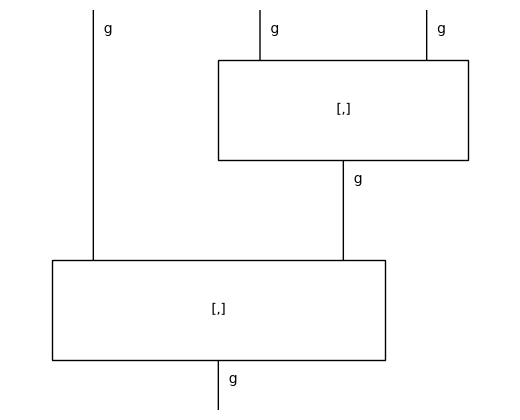

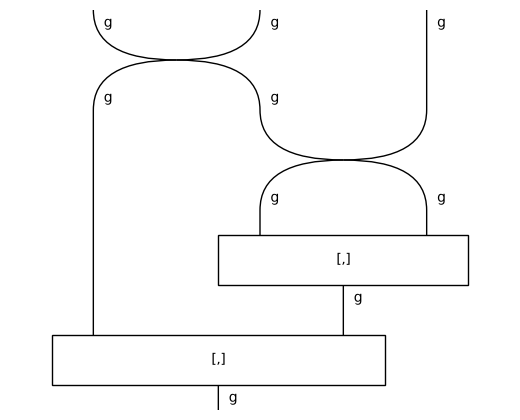

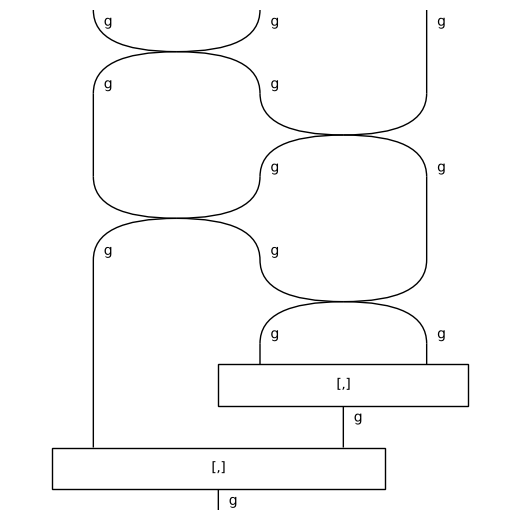

In [2]:
g = symmetric.Ty('g')
b = symmetric.Box('[,]', g @ g, g)
flip = symmetric.Swap(g, g)
inner = (symmetric.Id(g) @ b) >> b
cycle = (flip @ symmetric.Id(g)) >> (symmetric.Id(g) @ flip)
term2 = cycle >> inner
term3 = cycle >> cycle >> inner
inner.draw(figsize=(5, 4))
term2.draw(figsize=(5, 4))
term3.draw(figsize=(5, 5))

In [3]:
constants = np.zeros((3,3,3), dtype=int)
constants[0,1,1], constants[1,0,1] = 2, -2
constants[0,2,2], constants[2,0,2] = -2, 2
constants[1,2,0], constants[2,1,0] = 1, -1
F = tensor.Functor({g: tensor.Dim(3)}, {b: constants}, dom=symmetric.Category, dtype=int)
anti = F(b).array + F(flip >> b).array
jacobi = F(inner).array + F(term2).array + F(term3).array
print('(11.12) antisymmetry residual, all basis input pairs:\n', anti)
print('(11.13) Jacobi residual, all basis input triples:\n', jacobi)
print('antisymmetry =', np.all(anti == 0), '; Jacobi =', np.all(jacobi == 0))

(11.12) antisymmetry residual, all basis input pairs:
 [[[0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]]]
(11.13) Jacobi residual, all basis input triples:
 [[[[0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]]]


 [[[0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]]]


 [[[0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]]]]
antisymmetry = True ; Jacobi = True


The computation verifies this particular structure-constant model; it does not install a universal Jacobi rewrite.